# Time-Series analysis of AirBnb listings in Paris

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

**Importing the listing file and doing QA**

In [4]:
listings = pd.read_csv("Listings.csv", encoding="ISO-8859-1", low_memory=False)

In [5]:
listings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 279712 entries, 0 to 279711
Data columns (total 33 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   listing_id                   279712 non-null  int64  
 1   name                         279537 non-null  object 
 2   host_id                      279712 non-null  int64  
 3   host_since                   279547 non-null  object 
 4   host_location                278872 non-null  object 
 5   host_response_time           150930 non-null  object 
 6   host_response_rate           150930 non-null  float64
 7   host_acceptance_rate         166625 non-null  float64
 8   host_is_superhost            279547 non-null  object 
 9   host_total_listings_count    279547 non-null  float64
 10  host_has_profile_pic         279547 non-null  object 
 11  host_identity_verified       279547 non-null  object 
 12  neighbourhood                279712 non-null  object 
 13 

In [6]:
# columns like host_since are shown as having Dtype 'object'.
# this is used for storing text. We need to fix it so that the
# type for that column is date-time

In [7]:
listings["host_since"] = pd.to_datetime(listings["host_since"])
listings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 279712 entries, 0 to 279711
Data columns (total 33 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   listing_id                   279712 non-null  int64         
 1   name                         279537 non-null  object        
 2   host_id                      279712 non-null  int64         
 3   host_since                   279547 non-null  datetime64[ns]
 4   host_location                278872 non-null  object        
 5   host_response_time           150930 non-null  object        
 6   host_response_rate           150930 non-null  float64       
 7   host_acceptance_rate         166625 non-null  float64       
 8   host_is_superhost            279547 non-null  object        
 9   host_total_listings_count    279547 non-null  float64       
 10  host_has_profile_pic         279547 non-null  object        
 11  host_identity_verified    

In [8]:
# we can see that the data in 'host_since' column
# is now stored as 'datetime'
# For our analysis, we will not use all columns for simplicity.

**Let us analyse AirBnB listings in Paris**


---

To do so, we will preserve only the following columns:


1.   host_since
2.   neighbourhood
3.   city
4.   accomodates
5.   price



In [9]:
paris_listings = (listings.query("city =='Paris'")).loc[:, ["host_since", "neighbourhood", "city", "accommodates", "price"]]

paris_listings.info()


<class 'pandas.core.frame.DataFrame'>
Index: 64690 entries, 0 to 279711
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   host_since     64657 non-null  datetime64[ns]
 1   neighbourhood  64690 non-null  object        
 2   city           64690 non-null  object        
 3   accommodates   64690 non-null  int64         
 4   price          64690 non-null  int64         
dtypes: datetime64[ns](1), int64(2), object(2)
memory usage: 3.0+ MB


In [10]:
# We can see that the paris_listings dataframe contains information only about
# Paris.

**There are 64,690 rows in total. The first column i.e. 'host_since' has 64,657 rows with values. Around 30 rows have missing values.**

**Since we aim to do a time series analysis, we can choose to keep these missing rows in. They make a small sample size of missing values and will not meaningfully impact the analysis.**


In [11]:
# Let us now analyse statistical features of our date:
# mean, std deviation, count etc.

In [12]:
paris_listings.describe()

,host_since,accommodates,price
count,64657,64690.000000,64690.000000
mean,2015-11-01 11:06:05.528867584,3.037997,113.096445
min,2008-08-30 00:00:00,0.000000,0.000000
25%,2014-03-09 00:00:00,2.000000,59.000000
50%,2015-07-07 00:00:00,2.000000,80.000000
75%,2017-05-29 00:00:00,4.000000,120.000000
max,2021-02-07 00:00:00,16.000000,12000.000000
std,NaN,1.588766,214.433668


In [13]:
# The minimum value/min above displays '0' for both accomodation and price.
# This indicates a possible incorrect data entry since it is not possible to
# have an AirBnb with a capacity to host 0 guests or have it listed for 0 price.

**Let us examine how many rows contain the value '0'**

In [14]:
paris_listings.query("price == 0 and accommodates == 0").count()

,0
host_since,54
neighbourhood,54
city,54
accommodates,54
price,54


In [15]:
# 54 rows have values their values listed as '0'.
# This could indicate incomplete listings. 54 is a small number.
# So we will leave it in as there is no risk of this impacting the analysis later.

# Prepping Data for Visualisation

In [16]:
paris_listings_neighbourhood = paris_listings.groupby("neighbourhood").agg({"price":"mean"}).sort_values("price")
paris_listings_neighbourhood.head()

,price
neighbourhood,
Menilmontant,74.942257
Buttes-Chaumont,82.690182
Buttes-Montmartre,87.209479
Reuilly,89.058402
Popincourt,90.559459


In [17]:
# We can see that the cheapest neighbourhood in Paris is Menilmontant with an average price of 74.9.

In [18]:
paris_listings_neighbourhood.tail()

,price
neighbourhood,
Luxembourg,155.638639
Palais-Bourbon,156.856578
Passy,161.144635
Louvre,175.379972
Elysee,210.536765


In [19]:
# The most expensive neighbourhood was Elysee.

In [20]:
paris_listings_accommodates = (paris_listings.query("neighbourhood == 'Elysee'").groupby("accommodates").agg({"price" : "mean", "neighbourhood" : "count"}).sort_values("price"))

paris_listings_accommodates.head()


,price,neighbourhood
accommodates,,
0,0.000000,6
1,79.522222,90
3,152.828767,146
2,155.103352,716
4,212.096070,458


In [21]:
# we see that the listings which do not accommodate anyone i.e. o, command price of 0.

In [22]:
paris_listings_over_time = (
paris_listings.set_index ("host_since").resample ("Y").agg({"neighbourhood":"count", "price":"mean"}))
paris_listings_over_time.head()

/tmp/ipykernel_650/1727686063.py:2: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  paris_listings.set_index ("host_since").resample ("Y").agg({"neighbourhood":"count", "price":"mean"}))


,neighbourhood,price
host_since,,
2008-12-31,4,77.750000
2009-12-31,106,159.641509
2010-12-31,416,125.031250
2011-12-31,1339,124.828230
2012-12-31,4592,111.578615


In [23]:
# In the above output we see that:
# There were 4 listings  when AirBnb first launched.
# The average price of listings increased as more neighbourhoods signed up indicating number of hosts increased
# Prices then came as number of neighbourhood listings increased more indicating a fall in prices due to increased supply of AirBnb properties to rent.

# Visualizing our data

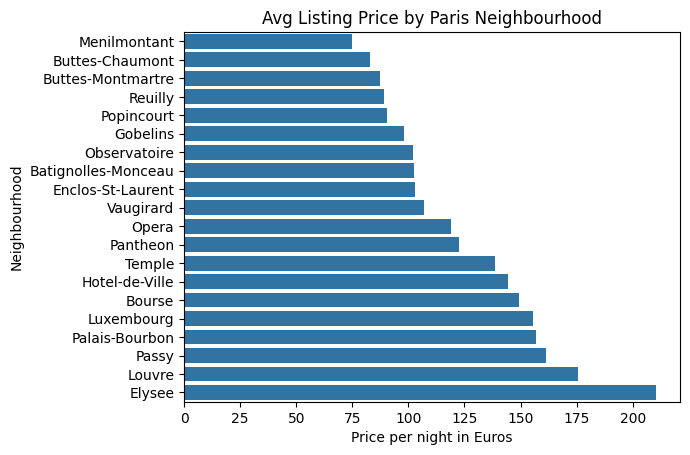

In [24]:
sns.barplot(x= paris_listings_neighbourhood["price"] , y=paris_listings_neighbourhood.index, legend=None)
plt.xlabel("Price per night in Euros")
plt.ylabel("Neighbourhood")
plt.title("Avg Listing Price by Paris Neighbourhood")

plt.show()

In [25]:
# We can see above that Elysee is the priciest neighbourhood, followed by Louvre, Bourse, etc.
# To a local, this might make sense. But maybe seeing it on a map can give us some context if we are not
# familiar with Paris. Let us do this out of curiousity.

In [26]:
neighbourhood_map = (
    paris_listings_neighbourhood
    .reset_index()[["neighbourhood", "price"]]
    .copy()
)

In [27]:
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter

geolocator = Nominatim(user_agent="paris_airbnb_analysis", timeout=10)
geocode = RateLimiter(geolocator.geocode, min_delay_seconds=1)

# Fetch a location for each neighbourhood
locations = neighbourhood_map["neighbourhood"].apply(
    lambda name: geocode(f"{name}, Paris, France")
)

# Extract coordinates into two new columns
neighbourhood_map["latitude"] = locations.apply(
    lambda loc: loc.latitude if loc else None
)

neighbourhood_map["longitude"] = locations.apply(
    lambda loc: loc.longitude if loc else None
)

neighbourhood_map

,neighbourhood,price,latitude,longitude
0,Menilmontant,74.942257,48.866704,2.383346
1,Buttes-Chaumont,82.690182,48.878396,2.381201
2,Buttes-Montmartre,87.209479,48.887436,2.329577
3,Reuilly,89.058402,48.844314,2.389842
4,Popincourt,90.559459,48.860430,2.375535
5,Gobelins,98.110184,48.836934,2.353921
6,Observatoire,101.866801,48.832851,2.326723
7,Batignolles-Monceau,102.612702,48.883226,2.318773
8,Enclos-St-Laurent,102.967156,NaN,NaN
9,Vaugirard,106.831330,48.839587,2.301280


In [28]:
import plotly.express as px

fig = px.scatter_map(
    neighbourhood_map.dropna(subset=["latitude", "longitude"]),
    lat="latitude",
    lon="longitude",
    hover_name="neighbourhood",
    color="price",
    size="price",
    color_continuous_scale="YlOrRd",
    map_style="open-street-map",
    zoom=11,
    labels={"price": "Average price (€)"},
    title="Average Airbnb price by Paris neighbourhood"
)

fig.show()

In [29]:
# Higher average prices appear around the central and western Seine corridor,
# near major sightseeing areas. This suggests that perhaps
# access to attractions and desirable locations may contribute to pricing.
# Obviously, we are making assumptions. But this is more interesting than seeing a simple
# Bar chart :)

In [30]:
# Let us now see how price varies according to capacity.

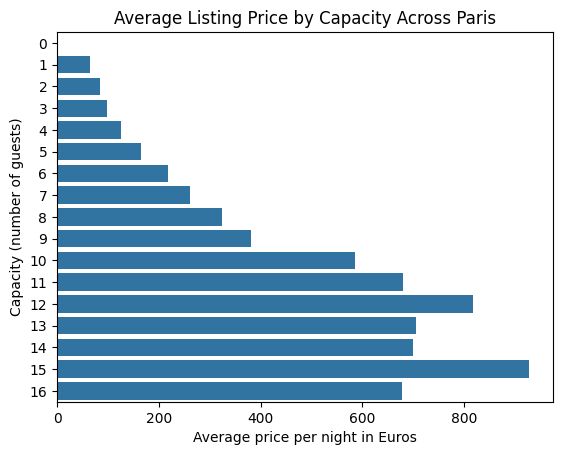

In [31]:
paris_listings_accommodates = (
    paris_listings
    .groupby("accommodates")
    .agg({"price": "mean"})
    .sort_index()
)

sns.barplot(
    x=paris_listings_accommodates["price"],
    y=paris_listings_accommodates.index,
    orient="h"
)

plt.xlabel("Average price per night in Euros")
plt.ylabel("Capacity (number of guests)")
plt.title("Average Listing Price by Capacity Across Paris")
plt.show()

In [32]:
# We can see above that the average listing price by capacity is highest for
# AirBnb rentals that host 15 people.
# One conclusion we can draw from this is that larger properties are better
# for families who travel together for a vacation. This is just one assumption.

<Axes: title={'center': 'New Hosts in Paris over Time'}, xlabel='host_since', ylabel='New Hosts'>

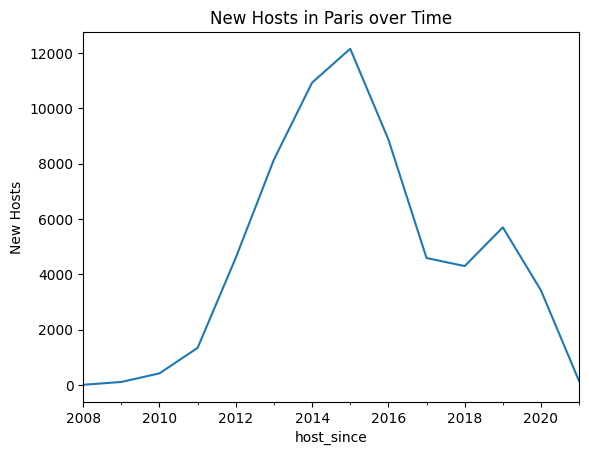

In [34]:
paris_listings_over_time["neighbourhood"].plot(
    ylabel = "New Hosts",
    title = "New Hosts in Paris over Time"
)

In [ ]:
# Findings:

# We can see that there were no hosts in Paris when AirBnb launched in 2008.
# At its peak in 2015, 12000 hosts were AirBnB hosts.
# In 2015, government stepped in to regulate this market. This created a sharp,
# drop in number in AirBnB hosts from 2015 onwards.

# Let us check what impact this had on AirBnb average prices in Paris.

<Axes: title={'center': 'Average AirBnb price in Paris over time'}, xlabel='host_since', ylabel='Average Price (Euros)'>

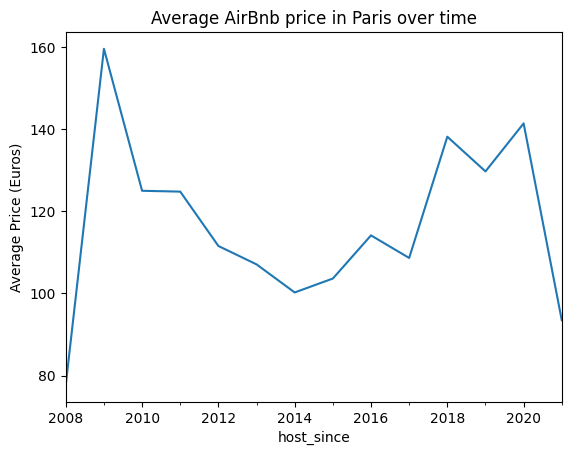

In [36]:
paris_listings_over_time["price"].plot(
    ylabel = "Average Price (Euros)",
    title = "Average AirBnb Price in Paris over time"
)

In [ ]:
# Findings:

# Average price in Paris was highest when AirBnb launched in 2008 as market
# was getting more estd.
# Avg price started to fall as more hosts joined AirBnb due to more competition.
# Government regulations were created in 2015, to bring in new norms for AirBnb.
# As number of hosts dropped, average prices started rising again.
# 2021 prices dropped off again, as COVID hit.

# This in itself does not highlight causality. It highlights a pattern explaining
# how prices rose and fell as market conditions and government regulations evolved.


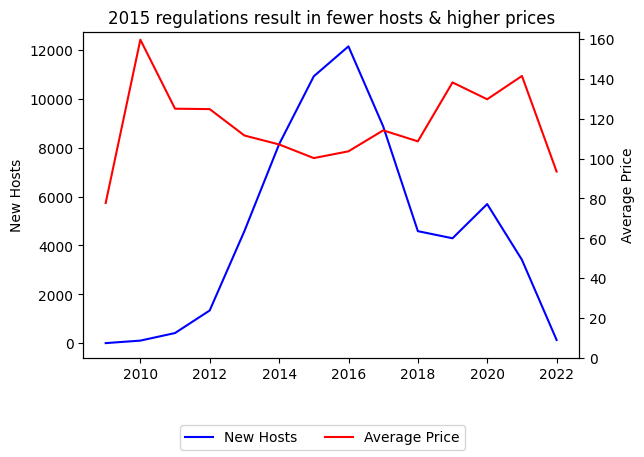

In [44]:
fig,ax = plt.subplots()
ax.plot(
    paris_listings_over_time.index,
    paris_listings_over_time["neighbourhood"],
label = "New Hosts",
    color = "blue"
)
ax.set_ylabel("New Hosts")


ax2 = ax.twinx()
ax2.plot(
    paris_listings_over_time.index,
    paris_listings_over_time["price"],
    label = "Average Price",
    color = "red"
)
ax2.set_ylim(0)
ax2.set_ylabel("Average Price")
ax.set_title("2015 regulations result in fewer hosts & higher prices")

fig.subplots_adjust(bottom=0.20)
fig.legend(loc="lower center", ncol=2)
plt.show()